## Compare results before and after tuning by manually computing and visualizing performance improvements across multiple models, ensuring a thorough analysis of convergence and generalization.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv('heart.csv')                          
X, y = df.drop(columns='target').values.astype(float), df['target'].values
print(X.shape, '| positive share:', y.mean().round(2))

(303, 13) | positive share: 0.54


In [2]:
def auc(t, s):
    sp, sn = s[t == 1], s[t == 0]
    return (sp[:, None] > sn[None, :]).mean() + 0.5 * (sp[:, None] == sn[None, :]).mean()

def metrics(t, p):
    q = np.clip(p, 1e-6, 1 - 1e-6)
    return dict(acc=np.mean((p > 0.5) == t), auc=auc(t, p), logloss=-np.mean(t * np.log(q) + (1 - t) * np.log(1 - q)))

In [3]:
models = {
    'LR':   (lambda **p: LogisticRegression(max_iter=1000, **p), dict(C=1),
             dict(C=[0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])),
    'kNN':  (lambda **p: KNeighborsClassifier(**p), dict(n_neighbors=5),
             dict(n_neighbors=[1, 3, 5, 9, 15, 21, 31])),
    'SVM':  (lambda **p: SVC(probability=True, random_state=0, **p), dict(C=1, gamma='scale'),
             dict(C=[0.3, 1, 3, 10], gamma=[0.003, 0.01, 0.03, 0.1])),
    'RF':   (lambda **p: RandomForestClassifier(100, random_state=0, **p), dict(max_depth=None, min_samples_leaf=1),
             dict(max_depth=[2, 3, 5], min_samples_leaf=[1, 3, 8])),
    'Tree': (lambda **p: DecisionTreeClassifier(random_state=0, **p), dict(max_depth=None, min_samples_leaf=1),
             dict(max_depth=[2, 3, 4, 5, 7, None], min_samples_leaf=[1, 5])),
}

def expand_grid(g):                                   
    combos = [{}]
    for key, values in g.items():
        combos = [{**c, key: v} for c in combos for v in values]
    return combos

In [4]:
def make_folds(n, k, seed): return np.array_split(np.random.default_rng(seed).permutation(n), k)

def scale(A, B): mu, sd = A.mean(0), A.std(0); return (A - mu) / sd, (B - mu) / sd      

def fit_proba(name, params, A, t, B):
    return models[name][0](**params).fit(A, t).predict_proba(B)[:, 1]

In [5]:
def grid_search(name, A, t, seed):
    combos = expand_grid(models[name][2]); np.random.default_rng(seed).shuffle(combos)   
    scores = []
    for p in combos:
        loss = []
        for f in make_folds(len(t), 3, seed):
            tr = np.setdiff1d(np.arange(len(t)), f); a, b = scale(A[tr], A[f])
            loss.append(metrics(t[f], fit_proba(name, p, a, t[tr], b))['logloss'])
        scores.append(np.mean(loss))
    best = int(np.argmin(scores))
    return combos[best], scores[best], np.minimum.accumulate(scores)                      

In [6]:
res = {n: {'before': [], 'after': []} for n in models}; curves = {n: [] for n in models}; inner_best = {n: [] for n in models}
for rep in range(2):
    folds = make_folds(len(X), 5, rep)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        A, B = scale(X[tr], X[te]); seed = rep * 5 + k
        for n, (_, default, _) in models.items():
            best, score, curve = grid_search(n, X[tr], y[tr], seed)
            curves[n].append(curve); inner_best[n].append(score)
            for tag, p in [('before', default), ('after', best)]:
                m = metrics(y[te], fit_proba(n, p, A, y[tr], B))
                m['train_acc'] = np.mean((fit_proba(n, p, A, y[tr], A) > 0.5) == y[tr])     
                res[n][tag].append(m)
print('Outer folds:', len(res['LR']['before']))

Outer folds: 10


In [7]:
rows = []
for n in models:
    g = lambda tag, c: np.array([m[c] for m in res[n][tag]])
    d = lambda c: g('after', c) - g('before', c); se = lambda v: v.std(ddof=1) / np.sqrt(len(v))
    rows.append((n, f"{g('before','acc').mean():.3f} -> {g('after','acc').mean():.3f}", f"{d('acc').mean():+.3f} +- {se(d('acc')):.3f}",
                 f"{g('before','auc').mean():.3f} -> {g('after','auc').mean():.3f}",
                 f"{g('before','logloss').mean():.3f} -> {g('after','logloss').mean():.3f}", f"{d('logloss').mean():+.3f} +- {se(d('logloss')):.3f}"))
pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Acc change', 'AUC', 'Log loss', 'Log loss change'])

,Model,Accuracy,Acc change,AUC,Log loss,Log loss change
0,LR,0.817 -> 0.823,+0.007 +- 0.003,0.906 -> 0.906,0.407 -> 0.401,-0.006 +- 0.007
1,kNN,0.830 -> 0.827,-0.003 +- 0.015,0.884 -> 0.909,0.859 -> 0.419,-0.440 +- 0.100
2,SVM,0.822 -> 0.828,+0.007 +- 0.014,0.902 -> 0.903,0.417 -> 0.400,-0.017 +- 0.008
3,RF,0.807 -> 0.815,+0.008 +- 0.009,0.901 -> 0.906,0.414 -> 0.414,-0.000 +- 0.008
4,Tree,0.743 -> 0.726,-0.016 +- 0.018,0.743 -> 0.799,3.557 -> 0.547,-3.010 +- 0.276


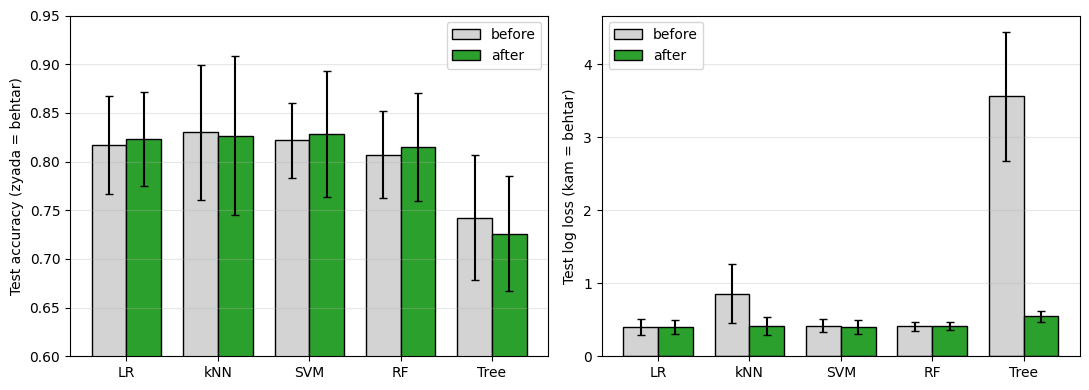

In [8]:
names = list(models); x = np.arange(len(names)); w = 0.38
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c, lab in [(axes[0], 'acc', 'Test accuracy (zyada = behtar)'), (axes[1], 'logloss', 'Test log loss (kam = behtar)')]:
    for j, (tag, col) in enumerate([('before', 'lightgray'), ('after', 'tab:green')]):
        v = [[m[c] for m in res[n][tag]] for n in names]
        ax.bar(x + (j - 0.5) * w, [np.mean(i) for i in v], w, yerr=[np.std(i) for i in v], color=col, edgecolor='k', capsize=3, label=tag)
    ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylabel(lab); ax.legend(); ax.grid(axis='y', alpha=0.3)
axes[0].set_ylim(0.6, 0.95)
plt.tight_layout(); plt.show()

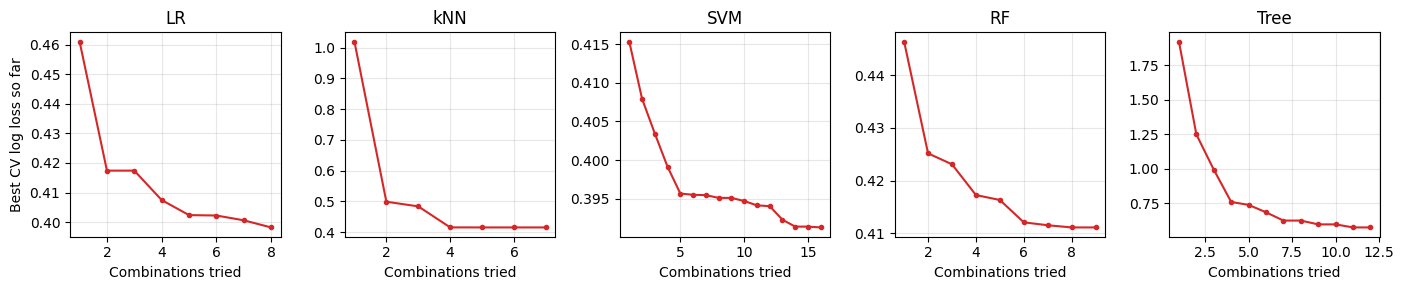

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, n in zip(axes, names):
    c = np.array(curves[n]); ax.plot(range(1, c.shape[1] + 1), c.mean(0), 'o-', color='tab:red', ms=3)
    ax.set_title(n); ax.set_xlabel('Combinations tried'); ax.grid(alpha=0.3)
axes[0].set_ylabel('Best CV log loss so far')
plt.tight_layout(); plt.show()

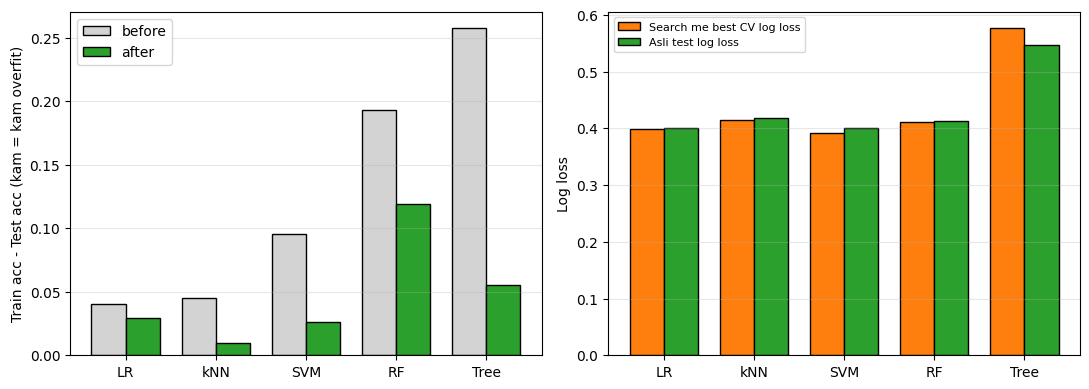

In [10]:
gap = lambda n, tag: np.mean([m['train_acc'] - m['acc'] for m in res[n][tag]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for j, (tag, col) in enumerate([('before', 'lightgray'), ('after', 'tab:green')]):
    axes[0].bar(x + (j - 0.5) * w, [gap(n, tag) for n in names], w, color=col, edgecolor='k', label=tag)
axes[0].set_xticks(x); axes[0].set_xticklabels(names); axes[0].set_ylabel('Train acc - Test acc (kam = kam overfit)'); axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
axes[1].bar(x - w / 2, [np.mean(inner_best[n]) for n in names], w, color='tab:orange', edgecolor='k', label='Search me best CV log loss')
axes[1].bar(x + w / 2, [np.mean([m['logloss'] for m in res[n]['after']]) for n in names], w, color='tab:green', edgecolor='k', label='Asli test log loss')
axes[1].set_xticks(x); axes[1].set_xticklabels(names); axes[1].set_ylabel('Log loss'); axes[1].legend(fontsize=8); axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

In [11]:
rows = [(n, f"{np.mean([m['train_acc'] for m in res[n]['before']]):.3f}", f"{np.mean([m['acc'] for m in res[n]['before']]):.3f}", f"{gap(n, 'before'):.3f}",
         f"{np.mean([m['train_acc'] for m in res[n]['after']]):.3f}", f"{np.mean([m['acc'] for m in res[n]['after']]):.3f}", f"{gap(n, 'after'):.3f}",
         f"{np.mean(inner_best[n]):.3f}", f"{np.mean([m['logloss'] for m in res[n]['after']]):.3f}") for n in names]
pd.DataFrame(rows, columns=['Model', 'Train acc (before)', 'Test acc (before)', 'Gap (before)', 'Train acc (after)', 'Test acc (after)', 'Gap (after)', 'Search CV loss', 'Test loss (after)'])

,Model,Train acc (before),Test acc (before),Gap (before),Train acc (after),Test acc (after),Gap (after),Search CV loss,Test loss (after)
0,LR,0.857,0.817,0.040,0.853,0.823,0.030,0.398,0.401
1,kNN,0.875,0.830,0.045,0.837,0.827,0.010,0.415,0.419
2,SVM,0.917,0.822,0.096,0.855,0.828,0.027,0.391,0.400
3,RF,1.000,0.807,0.193,0.934,0.815,0.119,0.411,0.414
4,Tree,1.000,0.743,0.257,0.782,0.726,0.056,0.576,0.547
